1. Instalações necessárias

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import random
from collections import deque

print("PyTorch version:", torch.__version__)

PyTorch version: 2.14.1+cpu


2. Classe do ambiente

In [ ]:
class CrossyRoadEnv:
    def __init__(self):
        self.rows = 8
        self.cols = 5
        self.reset()

    def reset(self):
        self.agent_pos = [0, 2] # Começa na base, coluna do meio
        self.max_row_reached = 0
        self.grid_terrain = self._generate_terrain()
        self.obstacles = self._init_obstacles()
        return self._get_state()

    def _generate_terrain(self):
        terrain = [0] # Início seguro (Grama)
        for _ in range(self.rows - 2):
            terrain.append(random.choice([0, 1, 2])) # 0: Grama, 1: Rua, 2: Rio
        terrain.append(0) # Meta
        return terrain

    def _init_obstacles(self):
        obstacles = {}
        for r in range(self.rows):
            if self.grid_terrain[r] == 1: # Rua
                obstacles[r] = {'pos': [random.randint(0, self.cols - 1)], 'dir': random.choice([-1, 1])}
            elif self.grid_terrain[r] == 2: # Rio
                obstacles[r] = {'pos': [random.randint(0, self.cols - 1)], 'dir': random.choice([-1, 1])}
            else:
                obstacles[r] = None
        return obstacles

    def step(self, action):
        # Ações: 0: Avançar, 1: Recuar, 2: Esquerda, 3: Direita, 4: Ficar parado[cite: 3]
        old_row = self.agent_pos[0]

        if action == 0:
            self.agent_pos[0] = min(self.rows - 1, self.agent_pos[0] + 1)
        elif action == 1:
            self.agent_pos[0] = max(0, self.agent_pos[0] - 1)
        elif action == 2:
            self.agent_pos[1] = max(0, self.agent_pos[1] - 1)
        elif action == 3:
            self.agent_pos[1] = min(self.cols - 1, self.agent_pos[1] + 1)
        elif action == 4:
            pass

        self._update_obstacles()
        current_terrain = self.grid_terrain[self.agent_pos[0]]

        # Dinâmica do Rio (carregado pelo tronco)[cite: 3]
        if current_terrain == 2:
            trunk_dir = self.obstacles[self.agent_pos[0]]['dir']
            self.agent_pos[1] += trunk_dir
            if self.agent_pos[1] < 0 or self.agent_pos[1] >= self.cols:
                return self._get_state(), -50.0, True, {} # Caiu na água

        done = False
        reward = -0.1 # Penalização leve por passo para evitar loops infinitos[cite: 4]

        # Chegar à linha de chegada[cite: 4]
        if self.agent_pos[0] == self.rows - 1:
            return self._get_state(), 50.0, True, {}

        # Colisão com carro[cite: 4]
        if current_terrain == 1:
            if self.agent_pos[1] in self.obstacles[self.agent_pos[0]]['pos']:
                return self._get_state(), -50.0, True, {}

        # Recompensas de progresso melhoradas[cite: 4]
        if self.agent_pos[0] > self.max_row_reached:
            reward = 5.0
            self.max_row_reached = self.agent_pos[0]
        elif self.agent_pos[0] < old_row:
            reward = -1.0

        return self._get_state(), reward, done, {}

    def _update_obstacles(self):
        for r in range(self.rows):
            if self.obstacles[r] is not None:
                obs = self.obstacles[r]
                obs['pos'] = [(p + obs['dir']) % self.cols for p in obs['pos']]

    def _get_state(self):
        terrain_array = np.array(self.grid_terrain, dtype=np.float32)
        agent_array = np.array(self.agent_pos, dtype=np.float32)
        return np.concatenate([agent_array, terrain_array])

3. Arquitetura DQN e Replay buffer

In [ ]:
class DQN(nn.Module):
    def __init__(self, input_dim, num_actions):
        super(DQN, self).__init__()
        self.fc = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, num_actions)
        )

    def forward(self, x):
        return self.fc(x)

class ReplayBuffer:
    def __init__(self, capacity):
        self.buffer = deque(maxlen=capacity)

    def push(self, state, action, reward, next_state, done):
        self.buffer.append((state, action, reward, next_state, done))

    def sample(self, batch_size):
        state, action, reward, next_state, done = zip(*random.sample(self.buffer, batch_size))
        return np.array(state), np.array(action), np.array(reward, dtype=np.float32), np.array(next_state), np.array(done, dtype=np.float32)

    def __len__(self):
        return len(self.buffer)

4. Realizando o treinamento

In [ ]:
env = CrossyRoadEnv()
input_dim = len(env.reset())
num_actions = 5

policy_net = DQN(input_dim, num_actions)
target_net = DQN(input_dim, num_actions)
target_net.load_state_dict(policy_net.state_dict())
target_net.eval()

optimizer = optim.Adam(policy_net.parameters(), lr=0.001)
memory = ReplayBuffer(capacity=10000)

gamma = 0.99
batch_size = 64
epsilon = 1.0
epsilon_min = 0.05
epsilon_decay = 0.99
episodes = 800
max_steps_per_episode = 200

# Lista para guardar as recompensas de cada episódio
rewards_history = []

def select_action(state, epsilon):
    if random.random() < epsilon:
        return random.randint(0, num_actions - 1)
    with torch.no_grad():
        state_tensor = torch.FloatTensor(state).unsqueeze(0)
        return policy_net(state_tensor).argmax().item()

def optimize_model():
    if len(memory) < batch_size:
        return

    states, actions, rewards, next_states, dones = memory.sample(batch_size)

    states = torch.FloatTensor(states)
    actions = torch.LongTensor(actions)
    rewards = torch.FloatTensor(rewards)
    next_states = torch.FloatTensor(next_states)
    dones = torch.FloatTensor(dones)

    q_values = policy_net(states)
    state_action_values = q_values.gather(1, actions.unsqueeze(1)).squeeze(1)

    with torch.no_grad():
        next_q_values = target_net(next_states).max(1)[0]
        expected_state_action_values = rewards + (gamma * next_q_values * (1 - dones))

    loss = nn.MSELoss()(state_action_values, expected_state_action_values)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

# Loop principal de treinamento
for e in range(episodes):
    state = env.reset()
    total_reward = 0
    done = False
    steps = 0

    while not done and steps < max_steps_per_episode:
        steps += 1
        action = select_action(state, epsilon)
        next_state, reward, done, _ = env.step(action)

        memory.push(state, action, reward, next_state, done)
        state = next_state
        total_reward += reward

        optimize_model()

    rewards_history.append(total_reward)
    epsilon = max(epsilon_min, epsilon * epsilon_decay)

    if (e + 1) % 50 == 0:
        print(f"Episódio {e+1}/{episodes} | Recompensa Total: {total_reward:.1f} | Passos: {steps} | Epsilon: {epsilon:.2f}")

    if (e + 1) % 10 == 0:
        target_net.load_state_dict(policy_net.state_dict())

print("Treinamento concluído com sucesso!")

Episódio 50/800 | Recompensa Total: -50.4 | Passos: 5 | Epsilon: 0.61
Episódio 100/800 | Recompensa Total: -21.4 | Passos: 12 | Epsilon: 0.37
Episódio 150/800 | Recompensa Total: 78.9 | Passos: 9 | Epsilon: 0.22
Episódio 200/800 | Recompensa Total: -51.2 | Passos: 200 | Epsilon: 0.13
Episódio 250/800 | Recompensa Total: -19.4 | Passos: 200 | Epsilon: 0.08
Episódio 300/800 | Recompensa Total: -32.3 | Passos: 200 | Epsilon: 0.05
Episódio 350/800 | Recompensa Total: -30.2 | Passos: 200 | Epsilon: 0.05
Episódio 400/800 | Recompensa Total: -35.5 | Passos: 24 | Epsilon: 0.05
Episódio 450/800 | Recompensa Total: -51.1 | Passos: 45 | Epsilon: 0.05
Episódio 500/800 | Recompensa Total: -15.8 | Passos: 200 | Epsilon: 0.05
Episódio 550/800 | Recompensa Total: -39.2 | Passos: 200 | Epsilon: 0.05
Episódio 600/800 | Recompensa Total: -51.6 | Passos: 17 | Epsilon: 0.05
Episódio 650/800 | Recompensa Total: -17.6 | Passos: 200 | Epsilon: 0.05
Episódio 700/800 | Recompensa Total: -66.2 | Passos: 187 | Ep

5. grafico

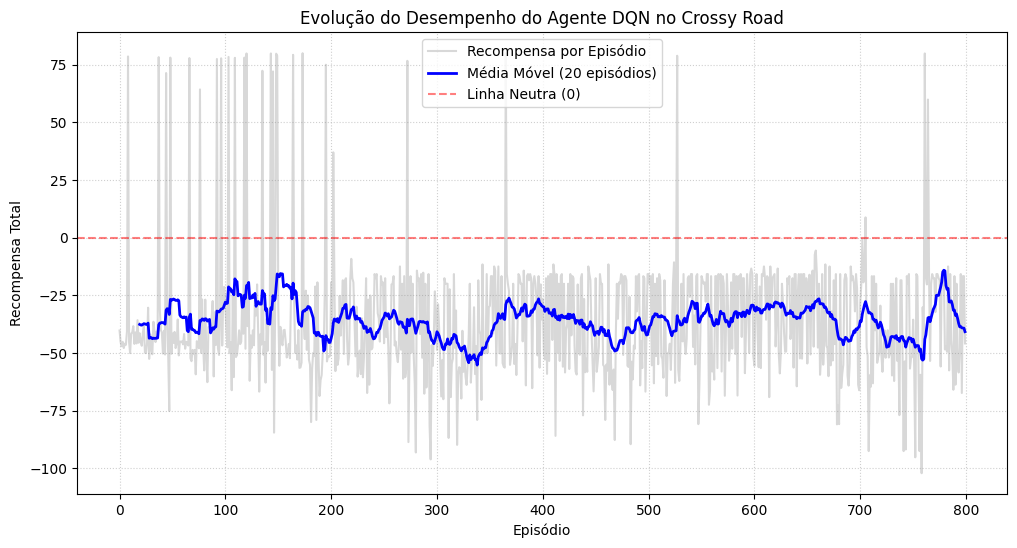

Gráfico gerado e guardado com sucesso!


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def moving_average(data, window_size=20):
    return np.convolve(data, np.ones(window_size)/window_size, mode='valid')

plt.figure(figsize=(12, 6))
plt.plot(rewards_history, alpha=0.3, color='gray', label='Recompensa por Episódio')

if len(rewards_history) >= 20:
    smoothed_rewards = moving_average(rewards_history, window_size=20)
    plt.plot(range(19, len(rewards_history)), smoothed_rewards, color='blue', linewidth=2, label='Média Móvel (20 episódios)')

plt.title('Evolução do Desempenho do Agente DQN no Crossy Road')
plt.xlabel('Episódio')
plt.ylabel('Recompensa Total')
plt.axhline(y=0, color='r', linestyle='--', alpha=0.5, label='Linha Neutra (0)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

plt.savefig('grafico_treino_dqn.png', dpi=300, bbox_inches='tight')
plt.show()

print("Gráfico gerado e guardado com sucesso!")